In [ ]:
import os
print(os.listdir('/content'))

['.config', '00210.tif', 'sample_data']


In [ ]:
!pip install -q imagecodecs

In [ ]:
!pip install imagecodecs

In [ ]:
import tifffile
import numpy as np

depth = tifffile.imread("/content/00210.tif")

print("Shape:", depth.shape)
print("Data type:", depth.dtype)
print("Minimum:", np.min(depth))
print("Maximum:", np.max(depth))
print("Unique values:", len(np.unique(depth)))
print("Valid pixels:", np.count_nonzero(depth > 0))

Shape: (720, 1280)
Data type: float32
Minimum: 0.0
Maximum: 29.68982
Unique values: 164440
Valid pixels: 428891


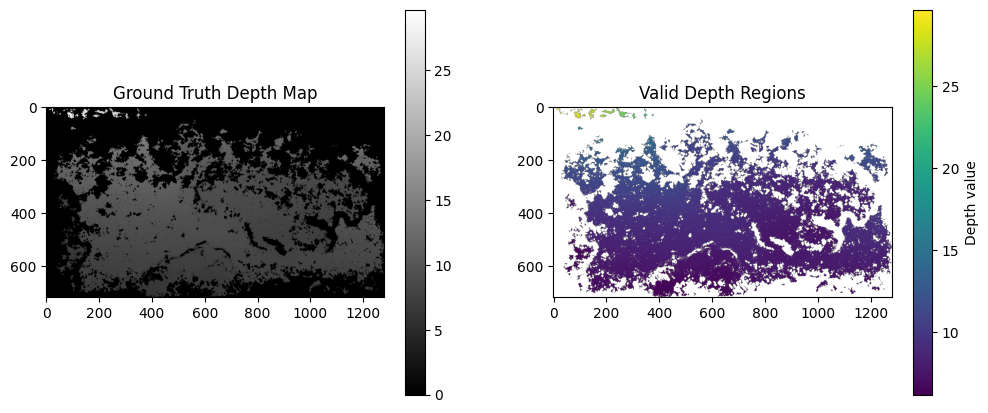

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth, cmap='gray')
plt.title("Ground Truth Depth Map")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(np.where(depth > 0, depth, np.nan), cmap='viridis')
plt.title("Valid Depth Regions")
plt.colorbar(label="Depth value")

plt.show()

In [ ]:
import os
print(os.listdir("/content"))

['.config', '00210.jpg', '00210.tif', 'sample_data']


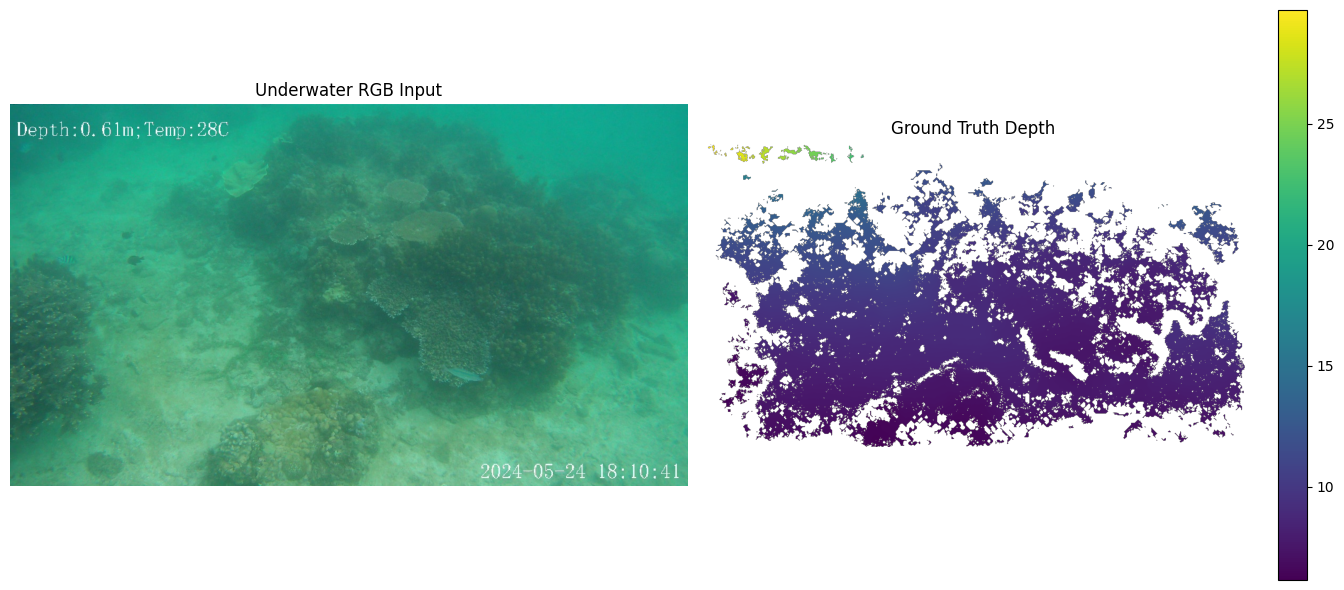

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import tifffile

rgb = Image.open("/content/00210.jpg").convert("RGB")
depth = tifffile.imread("/content/00210.tif")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Underwater RGB Input")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.where(depth > 0, depth, np.nan), cmap="viridis")
plt.title("Ground Truth Depth")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving video96.zip to video96.zip


In [ ]:
import zipfile
import os

zip_path = "/content/video96.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/uvmulti")

print("Extraction complete!")

Extraction complete!


In [ ]:
import os

extract_path = "/content/uvmulti"

for root, dirs, files in os.walk(extract_path):
    print(root, "→", len(files), "files")

    if root.count(os.sep) > 4:
        dirs[:] = []

/content/uvmulti → 0 files
/content/uvmulti/video96 → 0 files
/content/uvmulti/video96/sequence_enh → 255 files
/content/uvmulti/video96/images → 18 files
/content/uvmulti/video96/sequence → 255 files
/content/uvmulti/video96/dense_depth → 18 files
/content/uvmulti/video96/mask → 19 files
/content/uvmulti/video96/depth → 255 files


In [ ]:
print(os.listdir("/content/uvmulti"))

['video96']


In [ ]:
import os

base = "/content/uvmulti/video96"

rgb_folder = os.path.join(base, "sequence")
depth_folder = os.path.join(base, "depth")

rgb_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(rgb_folder)
    if f.endswith(".jpg")
}

depth_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(depth_folder)
    if f.endswith(".tif")
}

matched = sorted(rgb_files & depth_files)

print("RGB images:", len(rgb_files))
print("Depth maps:", len(depth_files))
print("Matched pairs:", len(matched))
print("Sample pairs:", matched[:10])

FileNotFoundError: [Errno 2] No such file or directory: '/content/uvmulti/video96/sequence'

In [ ]:
import os

base = "/content/uvmulti/video96"

rgb_folder = os.path.join(base, "sequence")
depth_folder = os.path.join(base, "depth")

rgb_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(rgb_folder)
    if f.endswith(".jpg")
}

depth_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(depth_folder)
    if f.endswith(".tif")
}

matched = sorted(rgb_files & depth_files)

print("RGB images:", len(rgb_files))
print("Depth maps:", len(depth_files))
print("Matched pairs:", len(matched))
print("First 10 pairs:", matched[:10])

RGB images: 255
Depth maps: 255
Matched pairs: 255
First 10 pairs: ['00000', '00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009']


In [ ]:
import tifffile
import numpy as np
from PIL import Image

for name in matched[:5]:
    img = Image.open(os.path.join(rgb_folder, name + ".jpg"))
    dep = tifffile.imread(os.path.join(depth_folder, name + ".tif"))

    print(
        name,
        "| RGB:", img.size,
        "| Depth:", dep.shape,
        "| Valid pixels:", np.count_nonzero(dep > 0)
    )

00000 | RGB: (1280, 720) | Depth: (720, 1280) | Valid pixels: 14321
00001 | RGB: (1280, 720) | Depth: (720, 1280) | Valid pixels: 17516
00002 | RGB: (1280, 720) | Depth: (720, 1280) | Valid pixels: 16273
00003 | RGB: (1280, 720) | Depth: (720, 1280) | Valid pixels: 19541
00004 | RGB: (1280, 720) | Depth: (720, 1280) | Valid pixels: 28509


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import tifffile
import numpy as np
import os

class UnderwaterDepthDataset(Dataset):

    def __init__(self, names, rgb_folder, depth_folder):
        self.names = names
        self.rgb_folder = rgb_folder
        self.depth_folder = depth_folder

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        rgb = Image.open(
            os.path.join(self.rgb_folder, name + ".jpg")
        ).convert("RGB")

        rgb = rgb.resize((320, 180))
        rgb = np.array(rgb, dtype=np.float32) / 255.0

        depth = tifffile.imread(
            os.path.join(self.depth_folder, name + ".tif")
        )

        depth = Image.fromarray(depth)
        depth = depth.resize((320, 180), Image.Resampling.NEAREST)
        depth = np.array(depth, dtype=np.float32)

        valid = (depth > 0) & np.isfinite(depth)

        depth = np.nan_to_num(depth, nan=0.0)

        rgb = torch.tensor(rgb).permute(2, 0, 1)
        depth = torch.tensor(depth).unsqueeze(0)
        valid = torch.tensor(valid.astype(np.float32)).unsqueeze(0)

        return rgb, depth, valid


dataset = UnderwaterDepthDataset(
    matched, rgb_folder, depth_folder
)

loader = DataLoader(dataset, batch_size=4, shuffle=True)

rgb, depth, valid = next(iter(loader))

print("RGB batch:", rgb.shape)
print("Depth batch:", depth.shape)
print("Valid mask:", valid.shape)

RGB batch: torch.Size([4, 3, 180, 320])
Depth batch: torch.Size([4, 1, 180, 320])
Valid mask: torch.Size([4, 1, 180, 320])


In [ ]:
import numpy as np
import os
import tifffile
import torch
from torch.utils.data import DataLoader

# Chronological split to reduce frame leakage
split = int(0.8 * len(matched))

train_names = matched[:split]
val_names = matched[split:]

train_dataset = UnderwaterDepthDataset(
    train_names, rgb_folder, depth_folder
)

val_dataset = UnderwaterDepthDataset(
    val_names, rgb_folder, depth_folder
)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False
)

# Estimate a robust depth normalization scale from training frames
samples = []

for name in train_names:
    d = tifffile.imread(os.path.join(depth_folder, name + ".tif"))
    values = d[::4, ::4]
    samples.append(values[np.isfinite(values) & (values > 0)])

depth_scale = float(np.percentile(np.concatenate(samples), 99))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Depth normalization scale:", depth_scale)
print("GPU available:", torch.cuda.is_available())

Training images: 204
Validation images: 51
Depth normalization scale: 872.43798828125
GPU available: True


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DepthCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.enc4 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.dec4 = ConvBlock(256 + 128, 128)
        self.dec3 = ConvBlock(128 + 64, 64)
        self.dec2 = ConvBlock(64 + 32, 32)
        self.dec1 = ConvBlock(32 + 16, 16)

        self.output = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = F.interpolate(b, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = F.interpolate(d4, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return torch.sigmoid(self.output(d1))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DepthCNN().to(device)

print("Model created!")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Model created!
Device: cuda
Parameters: 1965569


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 15

def masked_loss(pred, target, mask):
    return (torch.abs(pred - target) * mask).sum() / mask.sum().clamp(min=1)

train_losses = []
val_losses = []

for epoch in range(epochs):

    model.train()
    train_total = 0

    for rgb, depth, mask in train_loader:

        rgb = rgb.to(device)
        target = (depth / depth_scale).clamp(0, 1).to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        pred = model(rgb)
        loss = masked_loss(pred, target, mask)

        loss.backward()
        optimizer.step()

        train_total += loss.item()

    train_avg = train_total / len(train_loader)

    model.eval()
    val_total = 0

    with torch.no_grad():
        for rgb, depth, mask in val_loader:

            rgb = rgb.to(device)
            target = (depth / depth_scale).clamp(0, 1).to(device)
            mask = mask.to(device)

            pred = model(rgb)
            loss = masked_loss(pred, target, mask)

            val_total += loss.item()

    val_avg = val_total / len(val_loader)

    train_losses.append(train_avg)
    val_losses.append(val_avg)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_avg:.4f} "
        f"Val Loss: {val_avg:.4f}"
    )

Epoch [1/15] Train Loss: 0.2358 Val Loss: 0.1187
Epoch [2/15] Train Loss: 0.1497 Val Loss: 0.2136
Epoch [3/15] Train Loss: 0.1135 Val Loss: 0.1462
Epoch [4/15] Train Loss: 0.1040 Val Loss: 0.0740
Epoch [5/15] Train Loss: 0.0672 Val Loss: 0.1792
Epoch [6/15] Train Loss: 0.0647 Val Loss: 0.2952
Epoch [7/15] Train Loss: 0.0634 Val Loss: 0.0525
Epoch [8/15] Train Loss: 0.0500 Val Loss: 0.1189
Epoch [9/15] Train Loss: 0.1004 Val Loss: 0.1820
Epoch [10/15] Train Loss: 0.0597 Val Loss: 0.0659
Epoch [11/15] Train Loss: 0.0505 Val Loss: 0.2889
Epoch [12/15] Train Loss: 0.0367 Val Loss: 0.1850
Epoch [13/15] Train Loss: 0.0391 Val Loss: 0.1504
Epoch [14/15] Train Loss: 0.0305 Val Loss: 0.0390
Epoch [15/15] Train Loss: 0.0352 Val Loss: 0.1115


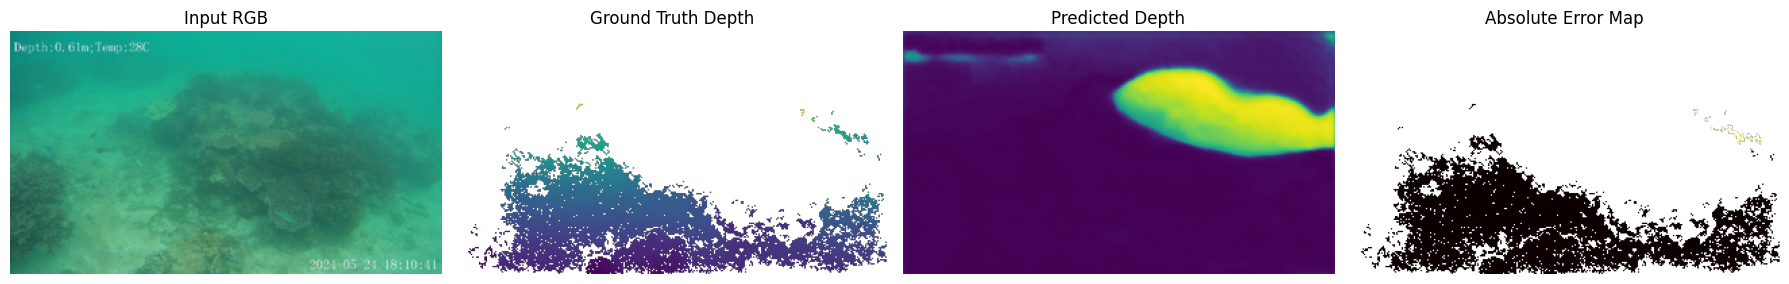

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

rgb, depth, mask = next(iter(val_loader))

with torch.no_grad():
    pred = model(rgb.to(device)).cpu().numpy()

rgb_img = rgb[0].permute(1, 2, 0).numpy()
gt = depth[0, 0].numpy()
valid = mask[0, 0].numpy() > 0
pred_depth = pred[0, 0] * depth_scale

error = np.abs(pred_depth - gt)

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(rgb_img)
plt.title("Input RGB")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(np.where(valid, gt, np.nan), cmap="viridis")
plt.title("Ground Truth Depth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred_depth, cmap="viridis")
plt.title("Predicted Depth")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(np.where(valid, error, np.nan), cmap="hot")
plt.title("Absolute Error Map")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
mae = error[valid].mean()
rmse = np.sqrt((error[valid] ** 2).mean())

print("MAE:", mae)
print("RMSE:", rmse)
print("Valid evaluation pixels:", valid.sum())

MAE: 10.233053
RMSE: 73.07847
Valid evaluation pixels: 13558


In [ ]:
mae = np.mean(np.abs(pred_depth[valid] - gt[valid]))

mse = np.mean((pred_depth[valid] - gt[valid]) ** 2)

rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 10.233053
MSE: 5340.4624
RMSE: 73.07847


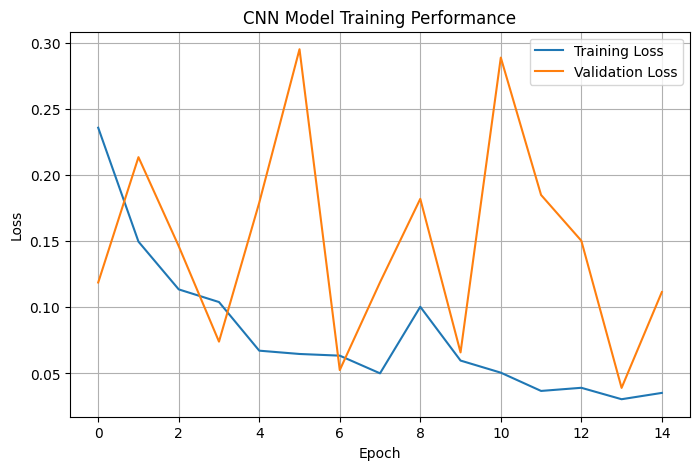

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Model Training Performance")
plt.legend()
plt.grid(True)

plt.savefig("training_loss.png", dpi=300)
plt.show()

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "depth_scale": depth_scale,
    "train_losses": train_losses,
    "val_losses": val_losses
}, "/content/underwater_depth_model.pth")

print("Model saved successfully!")

Model saved successfully!


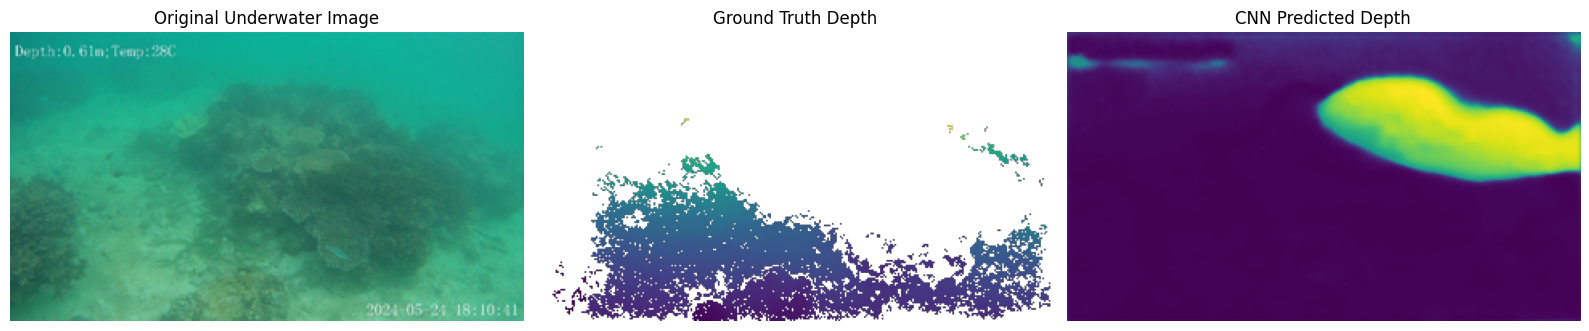

In [ ]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_img)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.where(valid, gt, np.nan), cmap="viridis")
plt.title("Ground Truth Depth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_depth, cmap="viridis")
plt.title("CNN Predicted Depth")
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/depth_comparison.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files

files.download("/content/underwater_depth_model.pth")
files.download("/content/training_loss.png")
files.download("/content/depth_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE"],
    "Value": [mae, mse, rmse]
})

results.to_csv("/content/evaluation_results.csv", index=False)

print(results)

  Metric        Value
0    MAE    10.233053
1    MSE  5340.462402
2   RMSE    73.078468


In [ ]:
print("Ground truth min:", gt[valid].min())
print("Ground truth max:", gt[valid].max())

print("Prediction min:", pred_depth.min())
print("Prediction max:", pred_depth.max())

print("Mean GT:", gt[valid].mean())
print("Mean prediction:", pred_depth[valid].mean())

Ground truth min: 6.348999
Ground truth max: 16.592285
Prediction min: 5.092715
Prediction max: 829.55835
Mean GT: 8.74863
Mean prediction: 18.815893


In [ ]:
mask = valid & np.isfinite(gt) & np.isfinite(pred_depth)

diff = pred_depth[mask] - gt[mask]

print("Valid pixels:", mask.sum())
print("MAE:", np.mean(np.abs(diff)))
print("MSE:", np.mean(diff ** 2))
print("RMSE:", np.sqrt(np.mean(diff ** 2)))

Valid pixels: 13558
MAE: 10.233053
MSE: 5340.4624
RMSE: 73.07847


In [ ]:
print("Depth scale:", depth_scale)

print("Raw prediction min:", pred.min())
print("Raw prediction max:", pred.max())
print("Raw prediction mean:", pred.mean())

print("Ground truth min:", gt[valid].min())
print("Ground truth max:", gt[valid].max())

Depth scale: 872.43798828125
Raw prediction min: 0.00556159
Raw prediction max: 0.9508508
Raw prediction mean: 0.086654566
Ground truth min: 6.348999
Ground truth max: 16.592285


In [ ]:
print("Prediction after scaling:")
print("Min:", (pred[0, 0] * depth_scale).min())
print("Max:", (pred[0, 0] * depth_scale).max())

print("Ground truth:")
print("Min:", gt[valid].min())
print("Max:", gt[valid].max())

Prediction after scaling:
Min: 5.092715
Max: 829.55835
Ground truth:
Min: 6.348999
Max: 16.592285


In [ ]:
import numpy as np
import tifffile
import os

all_depths = []

for name in train_names:
    d = tifffile.imread(os.path.join(depth_folder, name + ".tif"))
    values = d[np.isfinite(d) & (d > 0)]
    all_depths.extend(values)

all_depths = np.array(all_depths)

print("50th percentile:", np.percentile(all_depths, 50))
print("90th percentile:", np.percentile(all_depths, 90))
print("95th percentile:", np.percentile(all_depths, 95))
print("99th percentile:", np.percentile(all_depths, 99))
print("Maximum:", np.max(all_depths))

50th percentile: 9.861938
90th percentile: 653.0781
95th percentile: 754.8203
99th percentile: 866.041
Maximum: 2912.8281


In [ ]:
for name in train_names[:10]:
    d = tifffile.imread(os.path.join(depth_folder, name + ".tif"))
    v = d[np.isfinite(d) & (d > 0)]

    print(
        name,
        "P95:", np.percentile(v, 95),
        "P99:", np.percentile(v, 99),
        "Max:", np.max(v)
    )

00000 P95: 756.81836 P99: 785.10626 Max: 799.1582
00001 P95: 686.47705 P99: 828.5826 Max: 881.5703
00002 P95: 696.3656 P99: 777.83875 Max: 806.46875
00003 P95: 727.9326 P99: 791.0566 Max: 865.07227
00004 P95: 788.6481 P99: 840.91693 Max: 872.2012
00005 P95: 771.8402 P99: 822.68225 Max: 854.71875
00006 P95: 739.5774 P99: 779.69525 Max: 841.78125
00007 P95: 788.49603 P99: 839.92566 Max: 1064.8438
00008 P95: 799.13116 P99: 842.54584 Max: 880.7344
00009 P95: 740.2656 P99: 823.57935 Max: 856.70215


In [ ]:
import os
import numpy as np
import tifffile

print("TRAIN FRAME STATISTICS")

for name in train_names[:15]:
    d = tifffile.imread(
        os.path.join(depth_folder, name + ".tif")
    )

    v = d[np.isfinite(d) & (d > 0)]

    print(
        name,
        "| Median:", round(float(np.median(v)), 3),
        "| P95:", round(float(np.percentile(v, 95)), 3),
        "| Max:", round(float(np.max(v)), 3)
    )

print("\nVALIDATION FRAME STATISTICS")

for name in val_names[:15]:
    d = tifffile.imread(
        os.path.join(depth_folder, name + ".tif")
    )

    v = d[np.isfinite(d) & (d > 0)]

    print(
        name,
        "| Median:", round(float(np.median(v)), 3),
        "| P95:", round(float(np.percentile(v, 95)), 3),
        "| Max:", round(float(np.max(v)), 3)
    )

TRAIN FRAME STATISTICS
00000 | Median: 512.328 | P95: 756.818 | Max: 799.158
00001 | Median: 492.855 | P95: 686.477 | Max: 881.57
00002 | Median: 471.09 | P95: 696.366 | Max: 806.469
00003 | Median: 473.272 | P95: 727.933 | Max: 865.072
00004 | Median: 517.336 | P95: 788.648 | Max: 872.201
00005 | Median: 534.443 | P95: 771.84 | Max: 854.719
00006 | Median: 533.195 | P95: 739.577 | Max: 841.781
00007 | Median: 531.914 | P95: 788.496 | Max: 1064.844
00008 | Median: 538.034 | P95: 799.131 | Max: 880.734
00009 | Median: 499.173 | P95: 740.266 | Max: 856.702
00010 | Median: 513.834 | P95: 805.359 | Max: 879.381
00011 | Median: 504.416 | P95: 793.594 | Max: 940.48
00012 | Median: 508.937 | P95: 752.538 | Max: 930.984
00013 | Median: 527.227 | P95: 771.567 | Max: 972.588
00014 | Median: 539.688 | P95: 767.987 | Max: 905.619

VALIDATION FRAME STATISTICS
00204 | Median: 8.618 | P95: 11.119 | Max: 16.683
00205 | Median: 8.622 | P95: 11.32 | Max: 16.462
00206 | Median: 8.786 | P95: 10.942 | Max:

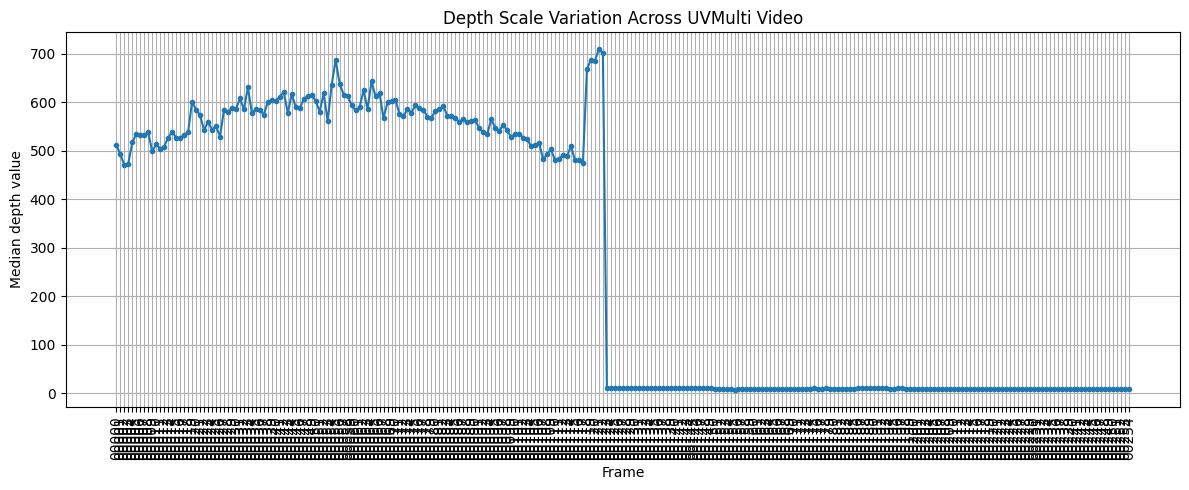

In [ ]:
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt

frame_medians = []
frame_names = []

for name in matched:
    d = tifffile.imread(
        os.path.join(depth_folder, name + ".tif")
    )

    valid_values = d[np.isfinite(d) & (d > 0)]

    frame_medians.append(np.median(valid_values))
    frame_names.append(name)

plt.figure(figsize=(12, 5))
plt.plot(frame_names, frame_medians, marker=".")
plt.xticks(rotation=90)
plt.xlabel("Frame")
plt.ylabel("Median depth value")
plt.title("Depth Scale Variation Across UVMulti Video")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import os
import tifffile

frame_stats = []

for name in matched:
    d = tifffile.imread(
        os.path.join(depth_folder, name + ".tif")
    )

    v = d[np.isfinite(d) & (d > 0)]

    frame_stats.append({
        "frame": name,
        "median": np.median(v),
        "p95": np.percentile(v, 95),
        "max": np.max(v)
    })

for i in range(1, len(frame_stats)):
    previous = frame_stats[i-1]["median"]
    current = frame_stats[i]["median"]

    ratio = current / max(previous, 1e-8)

    if ratio > 3 or ratio < 0.33:
        print(
            "Possible transition:",
            frame_stats[i-1]["frame"],
            "→",
            frame_stats[i]["frame"],
            "| Previous:", round(previous, 2),
            "| Current:", round(current, 2)
        )

Possible transition: 00122 → 00123 | Previous: 701.59 | Current: 11.19


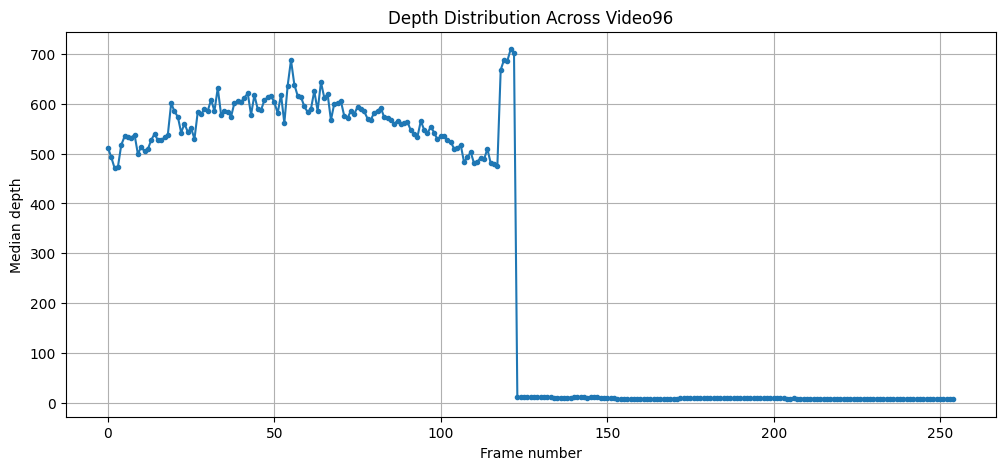

In [ ]:
import matplotlib.pyplot as plt

indices = [
    int(item["frame"])
    for item in frame_stats
]

medians = [
    item["median"]
    for item in frame_stats
]

plt.figure(figsize=(12, 5))
plt.plot(indices, medians, marker=".")
plt.xlabel("Frame number")
plt.ylabel("Median depth")
plt.title("Depth Distribution Across Video96")
plt.grid()
plt.show()

In [ ]:
consistent_names = [
    name for name in matched
    if 123 <= int(name) <= 254
]

consistent_names = sorted(
    consistent_names,
    key=lambda x: int(x)
)

print("Selected frames:", len(consistent_names))
print("First 5:", consistent_names[:5])
print("Last 5:", consistent_names[-5:])

Selected frames: 132
First 5: ['00123', '00124', '00125', '00126', '00127']
Last 5: ['00250', '00251', '00252', '00253', '00254']


In [ ]:
split = int(0.8 * len(consistent_names))

train_names = consistent_names[:split]
val_names = consistent_names[split:]

print("Training frames:", len(train_names))
print("Validation frames:", len(val_names))
print("Train range:", train_names[0], "-", train_names[-1])
print("Validation range:", val_names[0], "-", val_names[-1])

Training frames: 105
Validation frames: 27
Train range: 00123 - 00227
Validation range: 00228 - 00254


In [ ]:
import numpy as np
import os
import tifffile

train_depth_values = []

for name in train_names:
    d = tifffile.imread(
        os.path.join(depth_folder, name + ".tif")
    )

    v = d[np.isfinite(d) & (d > 0)]
    train_depth_values.extend(v[::4])

depth_scale = float(np.percentile(train_depth_values, 99))

print("New depth scale:", depth_scale)
print("Minimum:", np.min(train_depth_values))
print("Maximum:", np.max(train_depth_values))

New depth scale: 13.312835693359375
Minimum: 3.2982788
Maximum: 29.718506


In [ ]:
train_dataset = UnderwaterDepthDataset(
    train_names, rgb_folder, depth_folder
)

val_dataset = UnderwaterDepthDataset(
    val_names, rgb_folder, depth_folder
)

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 27
Validation batches: 7


In [ ]:
# Create a fresh model; don't reuse old weights
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DepthCNN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.0005
)

epochs = 15

print("Fresh CNN initialized!")
print("Device:", device)

Fresh CNN initialized!
Device: cuda


In [ ]:
import torch
import numpy as np

train_losses = []
val_losses = []

def masked_loss(pred, target, mask):
    error = torch.abs(pred - target) * mask
    return error.sum() / mask.sum().clamp(min=1)

epochs = 15

for epoch in range(epochs):

    model.train()
    train_total = 0

    for rgb, depth, mask in train_loader:

        rgb = rgb.to(device)
        target = (depth / depth_scale).clamp(0, 1).to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        pred = model(rgb)
        loss = masked_loss(pred, target, mask)

        loss.backward()
        optimizer.step()

        train_total += loss.item()

    train_avg = train_total / len(train_loader)

    model.eval()
    val_total = 0

    with torch.no_grad():
        for rgb, depth, mask in val_loader:

            rgb = rgb.to(device)
            target = (depth / depth_scale).clamp(0, 1).to(device)
            mask = mask.to(device)

            pred = model(rgb)
            loss = masked_loss(pred, target, mask)

            val_total += loss.item()

    val_avg = val_total / len(val_loader)

    train_losses.append(train_avg)
    val_losses.append(val_avg)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_avg:.4f} "
        f"Val Loss: {val_avg:.4f}"
    )

Epoch [1/15] Train Loss: 0.1253 Val Loss: 0.1618
Epoch [2/15] Train Loss: 0.0839 Val Loss: 0.1182
Epoch [3/15] Train Loss: 0.0718 Val Loss: 0.0707
Epoch [4/15] Train Loss: 0.0584 Val Loss: 0.0674
Epoch [5/15] Train Loss: 0.0562 Val Loss: 0.0702
Epoch [6/15] Train Loss: 0.0506 Val Loss: 0.0532
Epoch [7/15] Train Loss: 0.0460 Val Loss: 0.0401
Epoch [8/15] Train Loss: 0.0419 Val Loss: 0.0426
Epoch [9/15] Train Loss: 0.0389 Val Loss: 0.0445
Epoch [10/15] Train Loss: 0.0361 Val Loss: 0.0482
Epoch [11/15] Train Loss: 0.0336 Val Loss: 0.0469
Epoch [12/15] Train Loss: 0.0344 Val Loss: 0.0429
Epoch [13/15] Train Loss: 0.0290 Val Loss: 0.0400
Epoch [14/15] Train Loss: 0.0263 Val Loss: 0.0354
Epoch [15/15] Train Loss: 0.0268 Val Loss: 0.0434


In [ ]:
import numpy as np
import torch

model.eval()

all_errors = []
all_squared_errors = []
total_valid_pixels = 0

with torch.no_grad():
    for rgb, depth, mask in val_loader:

        rgb = rgb.to(device)
        target = depth.to(device)
        mask = mask.to(device)

        pred = model(rgb) * depth_scale

        valid = (mask > 0) & torch.isfinite(target)

        diff = pred - target

        errors = torch.abs(diff[valid])
        squared_errors = diff[valid] ** 2

        all_errors.extend(errors.cpu().numpy())
        all_squared_errors.extend(squared_errors.cpu().numpy())

        total_valid_pixels += valid.sum().item()

mae = np.mean(all_errors)
mse = np.mean(all_squared_errors)
rmse = np.sqrt(mse)

print("Full Validation Results")
print("-----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("Valid pixels:", total_valid_pixels)

Full Validation Results
-----------------------
MAE: 0.5769952
MSE: 0.8060637
RMSE: 0.8978105
Valid pixels: 816733


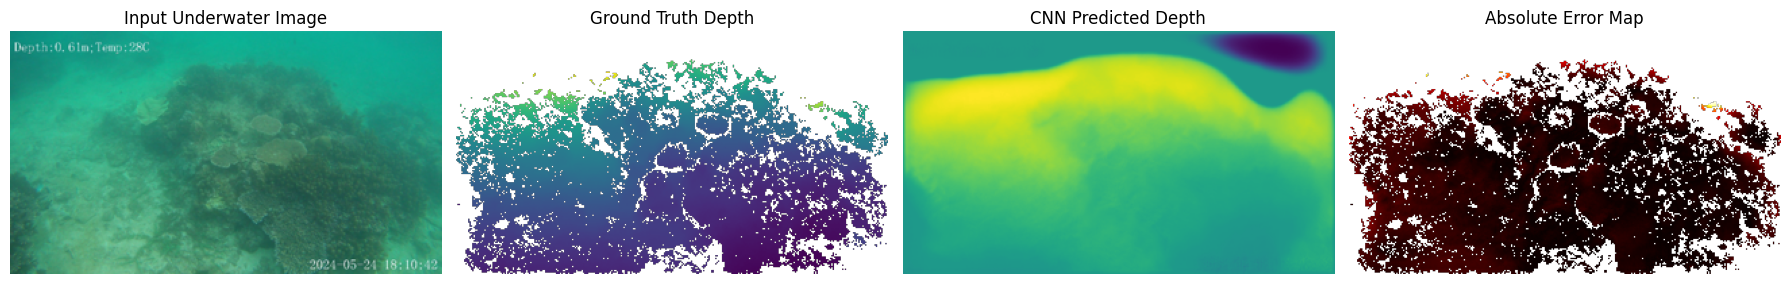

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

rgb, depth, mask = next(iter(val_loader))

with torch.no_grad():
    pred = model(rgb.to(device)).cpu().numpy()

rgb_img = rgb[0].permute(1, 2, 0).numpy()
gt = depth[0, 0].numpy()
valid = (mask[0, 0].numpy() > 0) & np.isfinite(gt)

pred_depth = pred[0, 0] * depth_scale

error = np.where(valid, np.abs(pred_depth - gt), np.nan)

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(rgb_img)
plt.title("Input Underwater Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(np.where(valid, gt, np.nan), cmap="viridis")
plt.title("Ground Truth Depth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred_depth, cmap="viridis")
plt.title("CNN Predicted Depth")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(error, cmap="hot")
plt.title("Absolute Error Map")
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/final_comparison.png", dpi=300)
plt.show()

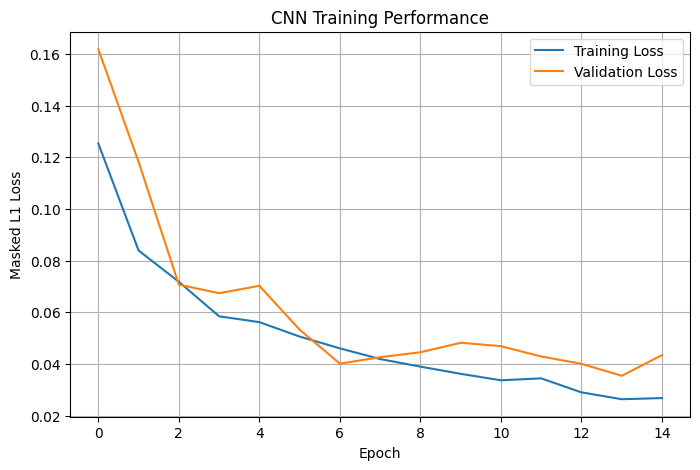

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Masked L1 Loss")
plt.title("CNN Training Performance")
plt.legend()
plt.grid(True)

plt.savefig("/content/final_loss_graph.png", dpi=300)
plt.show()

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "depth_scale": depth_scale,
    "train_losses": train_losses,
    "val_losses": val_losses
}, "/content/final_underwater_model.pth")

print("Final model saved!")

Final model saved!


In [ ]:
from google.colab import files

files.download("/content/final_underwater_model.pth")
files.download("/content/final_comparison.png")
files.download("/content/final_loss_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

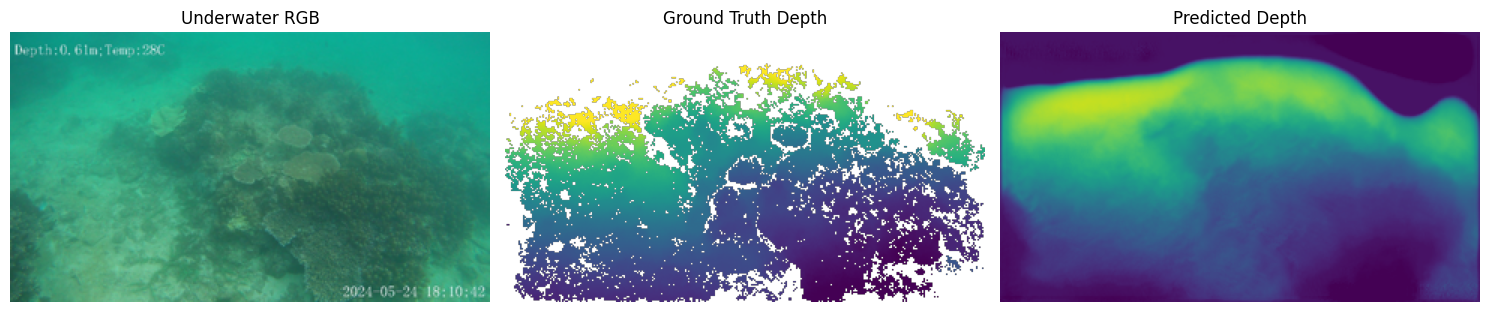

In [ ]:
vmin = np.percentile(gt[valid], 2)
vmax = np.percentile(gt[valid], 98)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_img)
plt.title("Underwater RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    np.where(valid, gt, np.nan),
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)
plt.title("Ground Truth Depth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    pred_depth,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax
)
plt.title("Predicted Depth")
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/final_same_scale.png", dpi=300)
plt.show()

In [ ]:
import pandas as pd

final_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE"],
    "Value": [mae, mse, rmse]
})

final_results.to_csv(
    "/content/final_evaluation_results.csv",
    index=False
)

print(final_results)

  Metric     Value
0    MAE  0.576995
1    MSE  0.806064
2   RMSE  0.897811


In [ ]:
import numpy as np
import torch

model.eval()

all_gt = []
all_pred = []
all_masks = []

with torch.no_grad():
    for images, depths, masks in val_loader:

        images = images.to(device)

        predictions = model(images)

        all_gt.append(depths.cpu().numpy())
        all_pred.append(predictions.cpu().numpy())
        all_masks.append(masks.cpu().numpy())

gt_depth = np.concatenate(all_gt, axis=0)
pred_depth = np.concatenate(all_pred, axis=0)
valid_mask = np.concatenate(all_masks, axis=0)

print("Ground truth shape:", gt_depth.shape)
print("Prediction shape:", pred_depth.shape)
print("Mask shape:", valid_mask.shape)

NameError: name 'model' is not defined

In [ ]:
import os
import torch

checkpoint_path = "/content/final_underwater_model.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

Checkpoint exists: False


In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

Files in /content:
['.config', 'sample_data']


In [ ]:
import os

print(os.listdir("/content")[:30])

['.config', '00040.tif', '00138.jpg', '00035.tif', '00120.png', '00116.tif', '00027.jpg', '00119.tif', '00195.tif', '00150.tif', '00162.tif', '00079.jpg', '00207.jpg', '00254.png', '00191.jpg', '00188.jpg', '00115.jpg', '00004.tif', '00179.jpg', '00092.tif', '00016.jpg', '00093.tif', '00108.jpg', '00052.jpg', '00027.tif', '00066.tif', '00238.tif', '00236.tif', '00208.jpg', '00190.tif']


In [ ]:
import os
from collections import Counter

files = os.listdir("/content")

jpg_files = [f for f in files if f.lower().endswith((".jpg", ".jpeg"))]
png_files = [f for f in files if f.lower().endswith(".png")]
tif_files = [f for f in files if f.lower().endswith((".tif", ".tiff"))]

print("JPG files:", len(jpg_files))
print("PNG files:", len(png_files))
print("TIF files:", len(tif_files))

print("\nJPG examples:", sorted(jpg_files)[:10])
print("TIF examples:", sorted(tif_files)[:10])
print("PNG examples:", sorted(png_files)[:10])

JPG files: 255
PNG files: 18
TIF files: 255

JPG examples: ['00000.jpg', '00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg', '00006.jpg', '00007.jpg', '00008.jpg', '00009.jpg']
TIF examples: ['00000.tif', '00001.tif', '00002.tif', '00003.tif', '00004.tif', '00005.tif', '00006.tif', '00007.tif', '00008.tif', '00009.tif']
PNG examples: ['00000.png', '00015.png', '00030.png', '00045.png', '00060.png', '00075.png', '00090.png', '00105.png', '00120.png', '00135.png']


In [ ]:
import os
import shutil

base = "/content"

rgb_dir = os.path.join(base, "sequence")
depth_dir = os.path.join(base, "depth")

os.makedirs(rgb_dir, exist_ok=True)
os.makedirs(depth_dir, exist_ok=True)

copied = 0
missing = []

for i in range(123, 255):
    name = f"{i:05d}"

    rgb_file = os.path.join(base, name + ".jpg")
    depth_file = os.path.join(base, name + ".tif")

    if os.path.exists(rgb_file) and os.path.exists(depth_file):
        shutil.copy2(rgb_file, os.path.join(rgb_dir, name + ".jpg"))
        shutil.copy2(depth_file, os.path.join(depth_dir, name + ".tif"))
        copied += 1
    else:
        missing.append(name)

print("Copied pairs:", copied)
print("Missing pairs:", missing)
print("RGB folder:", len(os.listdir(rgb_dir)))
print("Depth folder:", len(os.listdir(depth_dir)))

Copied pairs: 132
Missing pairs: []
RGB folder: 132
Depth folder: 132


In [ ]:
import cv2
import numpy as np
import os

rgb_path = "/content/sequence/00210.jpg"
depth_path = "/content/depth/00210.tif"

rgb = cv2.imread(rgb_path)
depth = cv2.imread(depth_path, cv2.IMREAD_UNCHANGED)

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Depth dtype:", depth.dtype)
print("Depth min:", np.nanmin(depth))
print("Depth max:", np.nanmax(depth))
print("Valid depth pixels:", np.sum(np.isfinite(depth) & (depth > 0)))

RGB shape: (720, 1280, 3)
Depth shape: (720, 1280)
Depth dtype: float32
Depth min: 0.0
Depth max: 29.68982
Valid depth pixels: 428891


In [ ]:
import os
import numpy as np
import cv2

rgb_dir = "/content/sequence"
depth_dir = "/content/depth"

frames = sorted(
    f for f in os.listdir(rgb_dir)
    if f.endswith(".jpg")
)

train_frames = frames[:105]
val_frames = frames[105:]

print("Training frames:", len(train_frames))
print("Validation frames:", len(val_frames))
print("Training range:", train_frames[0], "to", train_frames[-1])
print("Validation range:", val_frames[0], "to", val_frames[-1])

# Calculate depth scale using training frames only
depth_values = []

for f in train_frames:
    name = os.path.splitext(f)[0]
    depth = cv2.imread(
        os.path.join(depth_dir, name + ".tif"),
        cv2.IMREAD_UNCHANGED
    )
    valid = np.isfinite(depth) & (depth > 0)
    depth_values.extend(depth[valid])

depth_scale = np.percentile(depth_values, 99)

print("Depth scale (99th percentile):", depth_scale)

Training frames: 105
Validation frames: 27
Training range: 00123.jpg to 00227.jpg
Validation range: 00228.jpg to 00254.jpg
Depth scale (99th percentile): 13.311752


In [ ]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

DEPTH_SCALE = 13.311752
IMG_WIDTH = 320
IMG_HEIGHT = 180

class UnderwaterDataset(Dataset):
    def __init__(self, frames):
        self.frames = frames

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, idx):
        filename = self.frames[idx]
        name = os.path.splitext(filename)[0]

        rgb = cv2.imread(
            os.path.join("/content/sequence", filename)
        )
        rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
        rgb = cv2.resize(rgb, (IMG_WIDTH, IMG_HEIGHT))
        rgb = rgb.astype(np.float32) / 255.0

        depth = cv2.imread(
            os.path.join("/content/depth", name + ".tif"),
            cv2.IMREAD_UNCHANGED
        )

        depth = cv2.resize(
            depth, (IMG_WIDTH, IMG_HEIGHT),
            interpolation=cv2.INTER_NEAREST
        )

        mask = np.isfinite(depth) & (depth > 0)

        depth = np.nan_to_num(depth, nan=0.0, posinf=0.0)
        depth = np.clip(depth / DEPTH_SCALE, 0, 1)

        rgb = torch.from_numpy(rgb.transpose(2, 0, 1))
        depth = torch.from_numpy(depth.astype(np.float32)).unsqueeze(0)
        mask = torch.from_numpy(mask.astype(np.float32)).unsqueeze(0)

        return rgb, depth, mask

train_dataset = UnderwaterDataset(train_frames)
val_dataset = UnderwaterDataset(val_frames)

train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

rgb, depth, mask = next(iter(train_loader))

print("RGB batch shape:", rgb.shape)
print("Depth batch shape:", depth.shape)
print("Mask batch shape:", mask.shape)
print("Valid pixels in batch:", mask.sum().item())

Training batches: 14
Validation batches: 4
RGB batch shape: torch.Size([8, 3, 180, 320])
Depth batch shape: torch.Size([8, 1, 180, 320])
Mask batch shape: torch.Size([8, 1, 180, 320])
Valid pixels in batch: 135815.0


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DepthCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.enc4 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.dec4 = ConvBlock(256 + 128, 128)
        self.dec3 = ConvBlock(128 + 64, 64)
        self.dec2 = ConvBlock(64 + 32, 32)
        self.dec1 = ConvBlock(32 + 16, 16)

        self.final = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = F.interpolate(b, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = F.interpolate(d4, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return torch.sigmoid(self.final(d1))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DepthCNN().to(device)

print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Total parameters: 1965569


In [ ]:
import torch
import torch.nn as nn
import os

criterion = nn.L1Loss(reduction="none")
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

EPOCHS = 15

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    model.train()
    running_train_loss = 0.0

    for rgb, depth, mask in train_loader:
        rgb = rgb.to(device)
        depth = depth.to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        predictions = model(rgb)

        loss_map = criterion(predictions, depth)
        loss = (loss_map * mask).sum() / mask.sum().clamp(min=1)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # -------- VALIDATION --------
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for rgb, depth, mask in val_loader:
            rgb = rgb.to(device)
            depth = depth.to(device)
            mask = mask.to(device)

            predictions = model(rgb)

            loss_map = criterion(predictions, depth)
            loss = (loss_map * mask).sum() / mask.sum().clamp(min=1)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f}"
    )

# Save trained model
torch.save(model.state_dict(), "/content/final_underwater_model.pth")

print("\nTraining completed!")
print("Model saved successfully.")

Epoch [1/15] Train Loss: 0.1069 | Val Loss: 0.2137
Epoch [2/15] Train Loss: 0.0584 | Val Loss: 0.3208
Epoch [3/15] Train Loss: 0.0504 | Val Loss: 0.3079
Epoch [4/15] Train Loss: 0.0484 | Val Loss: 0.1462
Epoch [5/15] Train Loss: 0.0437 | Val Loss: 0.0845
Epoch [6/15] Train Loss: 0.0441 | Val Loss: 0.0574
Epoch [7/15] Train Loss: 0.0532 | Val Loss: 0.0623
Epoch [8/15] Train Loss: 0.0377 | Val Loss: 0.0659
Epoch [9/15] Train Loss: 0.0374 | Val Loss: 0.0372
Epoch [10/15] Train Loss: 0.0361 | Val Loss: 0.0484
Epoch [11/15] Train Loss: 0.0283 | Val Loss: 0.0354
Epoch [12/15] Train Loss: 0.0308 | Val Loss: 0.0468
Epoch [13/15] Train Loss: 0.0291 | Val Loss: 0.0454
Epoch [14/15] Train Loss: 0.0261 | Val Loss: 0.0427
Epoch [15/15] Train Loss: 0.0268 | Val Loss: 0.0363

Training completed!
Model saved successfully.


In [ ]:
import torch
import numpy as np
import pandas as pd

model.eval()

all_gt = []
all_pred = []

with torch.no_grad():
    for rgb, depth, mask in val_loader:
        rgb = rgb.to(device)

        pred = model(rgb).cpu().numpy()
        gt = depth.numpy()
        valid_mask = mask.numpy() > 0.5

        # Collect only valid depth pixels
        all_gt.append(gt[valid_mask])
        all_pred.append(pred[valid_mask])

# Combine all validation pixels
gt = np.concatenate(all_gt)
pred = np.concatenate(all_pred)

# Normalized metrics
mae_norm = np.mean(np.abs(gt - pred))
mse_norm = np.mean((gt - pred) ** 2)
rmse_norm = np.sqrt(mse_norm)

# Convert to original depth scale (not metres unless dataset confirms it)
gt_original = gt * DEPTH_SCALE
pred_original = pred * DEPTH_SCALE

mae = np.mean(np.abs(gt_original - pred_original))
mse = np.mean((gt_original - pred_original) ** 2)
rmse = np.sqrt(mse)

# Absolute Relative Error
abs_rel = np.mean(
    np.abs(gt_original - pred_original) / gt_original
)

# Delta 1 accuracy
ratio = np.maximum(
    gt_original / np.maximum(pred_original, 1e-8),
    pred_original / np.maximum(gt_original, 1e-8)
)
delta1 = np.mean(ratio < 1.25)

print("========== FINAL VALIDATION RESULTS ==========")
print("Valid pixels:", len(gt))
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("AbsRel:", abs_rel)
print("Delta1 Accuracy:", delta1)
print("\n========== NORMALIZED METRICS ==========")
print("MAE:", mae_norm)
print("MSE:", mse_norm)
print("RMSE:", rmse_norm)

# Save results for research paper
results = pd.DataFrame([{
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "AbsRel": abs_rel,
    "Delta1": delta1,
    "Valid_Pixels": len(gt),
    "Depth_Scale": DEPTH_SCALE
}])

results.to_csv(
    "/content/final_evaluation_results.csv",
    index=False
)

print("\nResults CSV saved successfully!")

========== FINAL VALIDATION RESULTS ==========
Valid pixels: 832610
MAE: 0.4687002
MSE: 0.35583007
RMSE: 0.59651494
AbsRel: 0.05659248
Delta1 Accuracy: 0.9943154658243355

========== NORMALIZED METRICS ==========
MAE: 0.035209503
MSE: 0.0020080393
RMSE: 0.044811152

Results CSV saved successfully!


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v2

# -------- MODEL B: MobileNetV2 Encoder-Decoder --------

class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[2:],
            mode="bilinear", align_corners=False
        )
        return self.block(torch.cat([x, skip], dim=1))


class MobileNetDepth(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = mobilenet_v2(weights=None).features

        self.dec4 = DecoderBlock(1280, 96, 256)
        self.dec3 = DecoderBlock(256, 32, 128)
        self.dec2 = DecoderBlock(128, 24, 64)
        self.dec1 = DecoderBlock(64, 16, 32)

        self.final = nn.Sequential(
            nn.Conv2d(32, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        input_size = x.shape[2:]

        for i, layer in enumerate(self.encoder):
            x = layer(x)

            if i == 1:
                s1 = x
            elif i == 3:
                s2 = x
            elif i == 6:
                s3 = x
            elif i == 13:
                s4 = x
            elif i == 18:
                bottleneck = x

        x = self.dec4(bottleneck, s4)
        x = self.dec3(x, s3)
        x = self.dec2(x, s2)
        x = self.dec1(x, s1)

        x = F.interpolate(
            x, size=input_size,
            mode="bilinear", align_corners=False
        )

        return self.final(x)


# -------- INITIALIZE --------

model_b = MobileNetDepth().to(device)

print("Model B: MobileNetV2 Encoder-Decoder")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model_b.parameters()))


# -------- TRAIN MODEL B --------

criterion_b = nn.L1Loss(reduction="none")
optimizer_b = torch.optim.Adam(
    model_b.parameters(), lr=0.0005
)

EPOCHS = 15
train_losses_b = []
val_losses_b = []

for epoch in range(EPOCHS):
    model_b.train()
    train_total = 0

    for rgb, depth, mask in train_loader:
        rgb = rgb.to(device)
        depth = depth.to(device)
        mask = mask.to(device)

        optimizer_b.zero_grad()

        pred = model_b(rgb)
        loss_map = criterion_b(pred, depth)
        loss = (loss_map * mask).sum() / mask.sum().clamp(min=1)

        loss.backward()
        optimizer_b.step()

        train_total += loss.item()

    train_loss = train_total / len(train_loader)
    train_losses_b.append(train_loss)

    model_b.eval()
    val_total = 0

    with torch.no_grad():
        for rgb, depth, mask in val_loader:
            rgb = rgb.to(device)
            depth = depth.to(device)
            mask = mask.to(device)

            pred = model_b(rgb)
            loss_map = criterion_b(pred, depth)
            loss = (loss_map * mask).sum() / mask.sum().clamp(min=1)

            val_total += loss.item()

    val_loss = val_total / len(val_loader)
    val_losses_b.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

torch.save(
    model_b.state_dict(),
    "/content/mobilenetv2_underwater_model.pth"
)

print("Model B training completed and saved!")


# -------- FINAL VALIDATION METRICS --------

model_b.eval()
all_gt, all_pred = [], []

with torch.no_grad():
    for rgb, depth, mask in val_loader:
        pred = model_b(rgb.to(device)).cpu().numpy()
        gt = depth.numpy()
        valid = mask.numpy() > 0.5

        all_gt.append(gt[valid])
        all_pred.append(pred[valid])

gt = __import__("numpy").concatenate(all_gt)
pred = __import__("numpy").concatenate(all_pred)

import numpy as np

gt_original = gt * DEPTH_SCALE
pred_original = pred * DEPTH_SCALE

mae = np.mean(np.abs(gt_original - pred_original))
mse = np.mean((gt_original - pred_original) ** 2)
rmse = np.sqrt(mse)

abs_rel = np.mean(
    np.abs(gt_original - pred_original) / gt_original
)

ratio = np.maximum(
    gt_original / np.maximum(pred_original, 1e-8),
    pred_original / np.maximum(gt_original, 1e-8)
)
delta1 = np.mean(ratio < 1.25)

print("\n====== MODEL B: FINAL RESULTS ======")
print("MAE:", round(float(mae), 5))
print("MSE:", round(float(mse), 5))
print("RMSE:", round(float(rmse), 5))
print("AbsRel:", round(float(abs_rel), 5))
print("Delta1:", round(float(delta1), 5))
print("Valid pixels:", len(gt))


Model B: MobileNetV2 Encoder-Decoder
Device: cuda
Parameters: 6622817
Epoch [1/15] Train Loss: 0.1179 | Val Loss: 0.2804
Epoch [2/15] Train Loss: 0.0667 | Val Loss: 0.2026
Epoch [3/15] Train Loss: 0.0677 | Val Loss: 0.1762
Epoch [4/15] Train Loss: 0.0508 | Val Loss: 0.1586
Epoch [5/15] Train Loss: 0.0526 | Val Loss: 0.1818
Epoch [6/15] Train Loss: 0.0469 | Val Loss: 0.1254
Epoch [7/15] Train Loss: 0.0409 | Val Loss: 0.0711
Epoch [8/15] Train Loss: 0.0463 | Val Loss: 0.0462
Epoch [9/15] Train Loss: 0.0388 | Val Loss: 0.0594
Epoch [10/15] Train Loss: 0.0359 | Val Loss: 0.0511
Epoch [11/15] Train Loss: 0.0390 | Val Loss: 0.0622
Epoch [12/15] Train Loss: 0.0349 | Val Loss: 0.0512
Epoch [13/15] Train Loss: 0.0441 | Val Loss: 0.0424
Epoch [14/15] Train Loss: 0.0373 | Val Loss: 0.0502
Epoch [15/15] Train Loss: 0.0299 | Val Loss: 0.0425
Model B training completed and saved!

====== MODEL B: FINAL RESULTS ======
MAE: 0.53959
MSE: 0.80943
RMSE: 0.89968
AbsRel: 0.05892
Delta1: 0.96585
Valid pixel